In [1]:
import torch
print("CUDA:", torch.cuda.is_available()) 
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA: True
GPU: Tesla T4


In [2]:
%pip install transformers accelerate scikit-learn torchvision datasets -q

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
import zipfile
import os
import shutil

zip_path = "/content/drive/MyDrive/ai-skin-care/skin-type-dataset.zip"
extract_to = "/content/skin-type-data"

if os.path.exists(extract_to):
    shutil.rmtree(extract_to)

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_to)

print("✅ Extracted")

✅ Extracted


In [5]:
import os
base = "/content/skin-type-data/skin-type-dataset"
for split in ["train", "valid", "test"]:
    split_path = os.path.join(base, split)
    if os.path.exists(split_path):
        print(f"\n{split}/")
        for cls in sorted(os.listdir(split_path)):
            cls_path = os.path.join(split_path, cls)
            if os.path.isdir(cls_path):
                count = len([f for f in os.listdir(cls_path) 
                            if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
                print(f"  {cls}: {count}")


train/
  combination: 248
  dry: 833
  normal: 976
  oily: 815

valid/
  combination: 63
  dry: 257
  normal: 263
  oily: 229

test/
  combination: 30
  dry: 113
  normal: 160
  oily: 106


In [6]:
from datasets import load_dataset

data_path = "/content/skin-type-data/skin-type-dataset"
dataset = load_dataset("imagefolder", data_dir=data_path)

print("Classes:", dataset["train"].features["label"].names)
print("Train:", len(dataset["train"]))
print("Valid:", len(dataset["validation"]))
print("Test:", len(dataset["test"]))

Resolving data files:   0%|          | 0/2872 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/812 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/409 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Classes: ['combination', 'dry', 'normal', 'oily']
Train: 2872
Valid: 812
Test: 409


In [7]:
from transformers import AutoImageProcessor, AutoModelForImageClassification
import torch

model_name = "google/vit-base-patch16-224-in21k"
processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModelForImageClassification.from_pretrained(
    model_name,
    num_labels=4,
    ignore_mismatched_sizes=True
).to("cuda")

print("✅ Model ready")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.bias     | MISSING    | 
classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Model ready


In [9]:
from torchvision import transforms

# Training ke liye — augmentation ON
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# Test/valid ke liye — augmentation OFF
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

def preprocess_train(batch):
    images = [train_transform(img.convert("RGB")) for img in batch["image"]]
    return {"pixel_values": torch.stack(images), "labels": batch["label"]}

def preprocess_test(batch):
    images = [test_transform(img.convert("RGB")) for img in batch["image"]]
    return {"pixel_values": torch.stack(images), "labels": batch["label"]}

train_ds = dataset["train"].with_transform(preprocess_train)
valid_ds = dataset["validation"].with_transform(preprocess_test)
test_ds = dataset["test"].with_transform(preprocess_test)

print("✅ Augmentation applied")
print(f"Train: {len(train_ds)} | Valid: {len(valid_ds)} | Test: {len(test_ds)}")

✅ Augmentation applied
Train: 2872 | Valid: 812 | Test: 409


In [10]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    predictions = np.argmax(eval_pred.predictions, axis=1)
    labels = eval_pred.label_ids
    
    accuracy = accuracy_score(labels, predictions)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="weighted", zero_division=0
    )
    
    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }

print("✅ Metrics ready")

✅ Metrics ready


In [11]:
from sklearn.utils.class_weight import compute_class_weight

train_labels = dataset["train"]["label"]
class_weights = compute_class_weight(
    "balanced",
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to("cuda")

class_names = dataset["train"].features["label"].names
print("Class weights:")
for name, w in zip(class_names, class_weights_tensor.cpu().numpy()):
    print(f"  {name}: {w:.3f}")

Class weights:
  combination: 2.895
  dry: 0.862
  normal: 0.736
  oily: 0.881


In [12]:
from transformers import Trainer
import torch.nn as nn

class WeightedTrainer(Trainer):
    def __init__(self, class_weights=None, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights
    
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        
        loss_fn = nn.CrossEntropyLoss(weight=self.class_weights)
        loss = loss_fn(logits, labels)
        
        return (loss, outputs) if return_outputs else loss

print("✅ WeightedTrainer defined")

✅ WeightedTrainer defined


In [13]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/skin-type-model-v3",
    num_train_epochs=8,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=3e-5,
    warmup_steps=200,
    weight_decay=0.01,
    logging_steps=50,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    report_to="none",
    remove_unused_columns=False,
)

print("✅ Training args ready")

✅ Training args ready


In [14]:
trainer = WeightedTrainer(
    class_weights=class_weights_tensor,
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    compute_metrics=compute_metrics,
)

print("✅ Weighted Trainer ready")

✅ Weighted Trainer ready


In [15]:
print("🚀 Training v3 shuru (augmentation + class weights)...")
print("Expected time: ~45-50 minute\n")

train_result = trainer.train()

print("\n✅ Training v3 complete!")
print(f"Final loss: {train_result.metrics['train_loss']:.4f}")

🚀 Training v3 shuru (augmentation + class weights)...
Expected time: ~45-50 minute



Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.353622,1.341219,0.343596,0.396426,0.343596,0.353217
2,1.237918,1.272836,0.422414,0.499094,0.422414,0.434502
3,1.079115,1.123059,0.538177,0.538567,0.538177,0.536583
4,0.827443,1.046962,0.589901,0.615698,0.589901,0.595685
5,0.591046,0.886285,0.663793,0.669945,0.663793,0.664456
6,0.447928,0.806375,0.720443,0.723587,0.720443,0.720675
7,0.341873,0.743479,0.741379,0.744483,0.741379,0.741390
8,0.259848,0.722534,0.741379,0.743513,0.741379,0.741277


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before


✅ Training v3 complete!
Final loss: 0.7814


In [16]:
results = trainer.evaluate(test_ds)

print("\n📊 Skin Type Model v3 — Test Results:")
print(f"Accuracy:  {results['eval_accuracy']:.2%}")
print(f"Precision: {results['eval_precision']:.2%}")
print(f"Recall:    {results['eval_recall']:.2%}")
print(f"F1 Score:  {results['eval_f1']:.2%}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.259848,0.642821,8,0.782396,0.788308,0.782396,0.783173



📊 Skin Type Model v3 — Test Results:
Accuracy:  78.24%
Precision: 78.83%
Recall:    78.24%
F1 Score:  78.32%


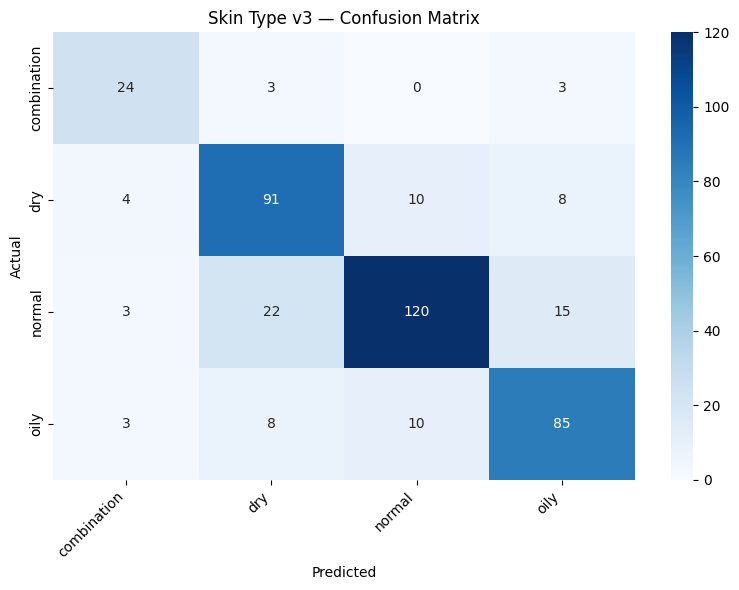

In [17]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=1)
labels = predictions.label_ids

cm = confusion_matrix(labels, preds)
class_names = dataset["train"].features["label"].names

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Skin Type v3 — Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [18]:
import os
import shutil

# Local save
save_path = "/content/skin-type-model-v3-final"
trainer.save_model(save_path)
processor.save_pretrained(save_path)

print("✅ Model saved locally")
print("Files:")
for f in os.listdir(save_path):
    size = os.path.getsize(os.path.join(save_path, f)) / (1024*1024)
    print(f"  {f}: {size:.1f} MB")

# Drive backup
drive_path = "/content/drive/MyDrive/ai-skin-care/skin-type-model-v3-final"
if os.path.exists(drive_path):
    shutil.rmtree(drive_path)
shutil.copytree(save_path, drive_path)

print(f"\n✅ Backed up to Drive: {drive_path}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model saved locally
Files:
  config.json: 0.0 MB
  model.safetensors: 327.3 MB
  preprocessor_config.json: 0.0 MB
  training_args.bin: 0.0 MB

✅ Backed up to Drive: /content/drive/MyDrive/ai-skin-care/skin-type-model-v3-final
